# Skin condition classifier — HAM10000 + EfficientNet

This is the baseline for a personal project: an app that looks at a photo of a skin lesion and
gives a best guess of what it might be. I'm building the model here first, then wrapping it in a
desktop app, and eventually a phone app.

**Important:** this is an educational / triage demo, *not* a medical device and *not* a diagnosis.
It only spits out a statistical guess. If you're actually worried about a spot on your skin, go
see a dermatologist. More on why you shouldn't trust this clinically in `docs/ETHICS.md`.

Rough plan for this notebook:
- grab the HAM10000 dataset (7 lesion types) and actually look at it
- split it carefully (by lesion, so the same lesion can't leak across train/test)
- fine-tune a pretrained EfficientNet-B0
- check precision/recall/F1 and a confusion matrix — paying attention to melanoma recall
- run a single-image "top-3 guesses" demo, which is basically what the app will do

## 0. Setup & environment

In [2]:
# Colab already has torch/torchvision. Install the few extras we need (quietly).
# Safe to re-run; pip skips what's already present.
import sys, subprocess
def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

pip_install("kaggle", "seaborn", "scikit-learn")

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Colab: Runtime -> Change runtime type -> T4 GPU.")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [19]:
import os, glob, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import EfficientNet_B0_Weights

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

# keep runs reproducible
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# the knobs I end up tweaking the most
IMG_SIZE    = 224     # efficientnet-b0 wants 224x224
BATCH_SIZE  = 32
EPOCHS      = 20       # 5 just to confirm it trains - bump to 15-25 for real results
LR          = 1e-4
NUM_WORKERS = 2       # set to 0 if you're on Windows and the dataloader workers act up
DATA_DIR    = Path("data/ham10000")
BEST_MODEL_PATH = Path("skin_classifier_efficientnet_b0.pt")

Using device: cuda


## 1. Get the data (HAM10000)

We use the Kaggle mirror `kmader/skin-cancer-mnist-ham10000`. You need a free Kaggle API
token (`kaggle.json`): Kaggle -> Account -> Settings -> API -> "Create New Token".

The cell below will:
- skip downloading if the data is already present, otherwise
- ask you to upload `kaggle.json` (on Colab), then download + unzip.

Already have the data? Set `DATA_DIR` above to your folder and skip the download.
See `docs/DATA.md` for details and an alternative (Harvard Dataverse) source.

In [4]:
def have_data(d):
    meta = list(d.glob("**/HAM10000_metadata.csv"))
    imgs = list(d.glob("**/*.jpg"))
    return len(meta) > 0 and len(imgs) > 1000

DATA_DIR.mkdir(parents=True, exist_ok=True)

if have_data(DATA_DIR):
    print("Data already present at", DATA_DIR.resolve())
else:
    kdir = Path.home() / ".kaggle"; kdir.mkdir(exist_ok=True)
    token = kdir / "kaggle.json"
    if not token.exists() and not Path("kaggle.json").exists():
        try:
            from google.colab import files  # type: ignore
            print("Upload your kaggle.json ...")
            files.upload()
        except Exception:
            print("Place kaggle.json in this folder (or ~/.kaggle/) and re-run this cell.")
    if Path("kaggle.json").exists():
        shutil.copy("kaggle.json", token)
    try:
        os.chmod(token, 0o600)
    except Exception:
        pass

    print("Downloading + unzipping HAM10000 (~2.6 GB). Takes a few minutes ...")
    import kaggle
    kaggle.api.authenticate()
    kaggle.api.dataset_download_files("kmader/skin-cancer-mnist-ham10000",
                                      path=str(DATA_DIR), unzip=True)
    print("Done. Data at", DATA_DIR.resolve())

Upload your kaggle.json ...


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
Done. Data at /content/data/ham10000


### Build the image table (map every image to its label + file path)

In [5]:
meta_path = next(DATA_DIR.glob("**/HAM10000_metadata.csv"))
df = pd.read_csv(meta_path)

# Map image_id -> file path (images live across two sub-folders).
image_paths = {Path(p).stem: p for p in glob.glob(str(DATA_DIR / "**" / "*.jpg"), recursive=True)}
df["path"] = df["image_id"].map(image_paths)
missing = df["path"].isna().sum()
print(f"Rows: {len(df)} | images matched: {len(df) - missing} | missing: {missing}")
df = df.dropna(subset=["path"]).reset_index(drop=True)

FULL_NAMES = {
    "akiec": "Actinic keratoses / Bowen's",
    "bcc":   "Basal cell carcinoma",
    "bkl":   "Benign keratosis",
    "df":    "Dermatofibroma",
    "mel":   "Melanoma",
    "nv":    "Melanocytic nevus",
    "vasc":  "Vascular lesion",
}
CLASSES = sorted(df["dx"].unique())            # deterministic class order
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df["label"] = df["dx"].map(CLASS_TO_IDX)
print("Classes:", CLASSES)
df.head()

Rows: 10015 | images matched: 10015 | missing: 0
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,data/ham10000/ham10000_images_part_1/ISIC_0027...,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,data/ham10000/ham10000_images_part_1/ISIC_0025...,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,data/ham10000/ham10000_images_part_1/ISIC_0026...,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,data/ham10000/ham10000_images_part_1/ISIC_0025...,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,data/ham10000/HAM10000_images_part_2/ISIC_0031...,2


## 2. Explore the data (EDA)

The most important thing to notice: **the classes are wildly imbalanced.** ~67% of all
images are `nv` (common moles). A model that always predicts `nv` would score ~67% accuracy
while catching zero melanomas — which is exactly why we don't trust accuracy here.

       count  percent
dx                   
akiec    327      3.3
bcc      514      5.1
bkl     1099     11.0
df       115      1.1
mel     1113     11.1
nv      6705     66.9
vasc     142      1.4


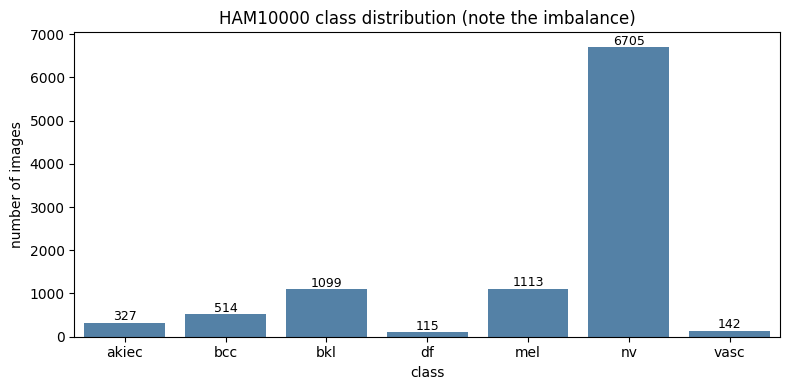

In [6]:
counts = df["dx"].value_counts().reindex(CLASSES)
pct = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": pct}))

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue")
plt.title("HAM10000 class distribution (note the imbalance)")
plt.ylabel("number of images"); plt.xlabel("class")
for i, v in enumerate(counts.values):
    plt.text(i, v + 50, str(int(v)), ha="center", fontsize=9)
plt.tight_layout(); plt.show()

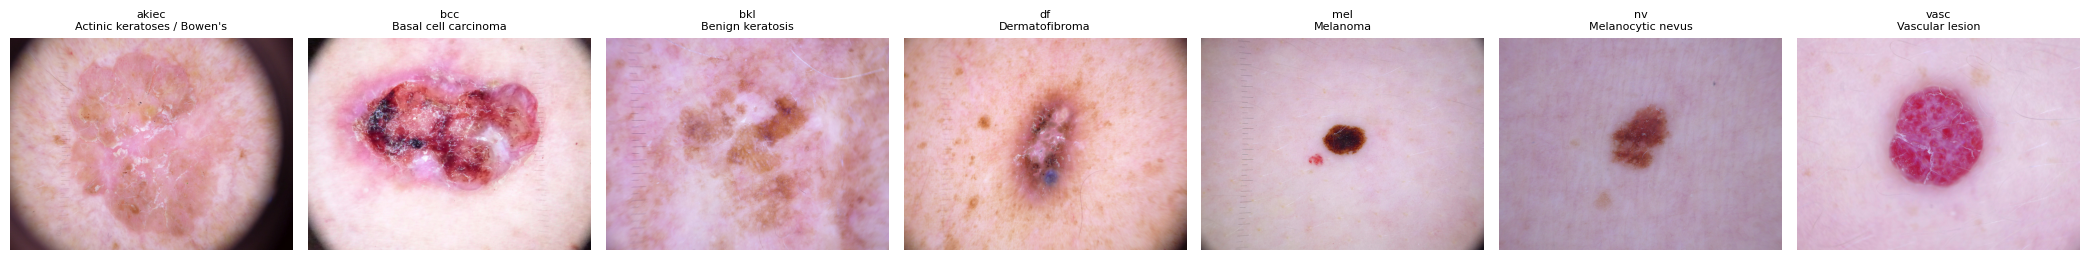

In [7]:
# One example image per class.
fig, axes = plt.subplots(1, len(CLASSES), figsize=(3 * len(CLASSES), 3))
for ax, c in zip(axes, CLASSES):
    row = df[df["dx"] == c].iloc[0]
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.set_title(f"{c}\n{FULL_NAMES[c]}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Train / validation / test split (grouped by lesion)

Many lesions were photographed multiple times, so several rows share a `lesion_id`. If two
photos of the *same* lesion land in different splits, the test score is inflated by **data
leakage**. We split **by `lesion_id`** so an entire lesion stays within one split.

In [8]:
def grouped_split(frame, groups, test_frac, seed=SEED):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_frac, random_state=seed)
    a_idx, b_idx = next(gss.split(frame, groups=groups))
    return frame.iloc[a_idx].reset_index(drop=True), frame.iloc[b_idx].reset_index(drop=True)

# 70% train / 15% val / 15% test
train_df, temp_df = grouped_split(df, df["lesion_id"], test_frac=0.30)
val_df,  test_df  = grouped_split(temp_df, temp_df["lesion_id"], test_frac=0.50)

overlap = (set(train_df.lesion_id) & set(val_df.lesion_id)) | \
          (set(train_df.lesion_id) & set(test_df.lesion_id)) | \
          (set(val_df.lesion_id)  & set(test_df.lesion_id))
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}  | lesion overlap: {len(overlap)}")

train=7002  val=1519  test=1494  | lesion overlap: 0


## 4. Datasets, augmentation & imbalance handling

- **Augmentation** (flips/rotations/jitter) on the training set makes the model more robust.
- **Class-weighted loss** counters the imbalance: rare classes get a bigger penalty when missed.
  Weights are computed from the **training set only** (never peek at val/test).

In [9]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE + 32),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class SkinDataset(Dataset):
    def __init__(self, frame, tf):
        self.frame = frame.reset_index(drop=True)
        self.tf = tf
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        img = Image.open(row["path"]).convert("RGB")
        return self.tf(img), int(row["label"])

train_ds = SkinDataset(train_df, train_tf)
val_ds   = SkinDataset(val_df,   eval_tf)
test_ds  = SkinDataset(test_df,  eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

class_weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_df["label"].values)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print("Class weights:", {CLASSES[i]: round(float(w), 2) for i, w in enumerate(class_weights)})

Class weights: {'akiec': 4.83, 'bcc': 2.63, 'bkl': 1.35, 'df': 11.24, 'mel': 1.3, 'nv': 0.21, 'vasc': 10.42}


## 5. Model — EfficientNet-B0 (transfer learning)

We load EfficientNet-B0 pretrained on ImageNet and swap its final layer for a fresh 7-class
head. The pretrained backbone already knows generic visual features (edges, textures, shapes);
fine-tuning adapts them to skin lesions with far less data than training from scratch.

In [22]:
def build_model(num_classes):
    weights = EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    in_features = model.classifier[1].in_features      # 1280 for B0
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

model = build_model(len(CLASSES)).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"EfficientNet-B0 ready: {len(CLASSES)} output classes, {n_params/1e6:.1f}M trainable params")

EfficientNet-B0 ready: 7 output classes, 4.0M trainable params


## 6. Training loop

We select the **best model by validation macro-F1** (the unweighted average of per-class F1),
not by accuracy — because accuracy rewards always guessing the majority class.

In [23]:
from tqdm.auto import tqdm

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = (DEVICE.type == "cuda")
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, all_preds, all_true = 0.0, [], []
    with torch.set_grad_enabled(train):
        for imgs, labels in tqdm(loader, leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            if train:
                optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                out = model(imgs)
                loss = criterion(out, labels)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * imgs.size(0)
            all_preds.extend(out.argmax(1).detach().cpu().numpy())
            all_true.extend(labels.detach().cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    macro_f1 = f1_score(all_true, all_preds, average="macro")
    return avg_loss, macro_f1

/tmp/ipykernel_7389/2047380649.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


In [24]:
best_f1 = 0.0
history = {"train_loss": [], "val_loss": [], "val_f1": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_f1 = run_epoch(train_loader, train=True)
    va_loss, va_f1 = run_epoch(val_loader, train=False)
    scheduler.step()
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["val_f1"].append(va_f1)
    flag = ""
    if va_f1 > best_f1:
        best_f1 = va_f1
        torch.save({"model_state": model.state_dict(),
                    "classes": CLASSES,
                    "full_names": FULL_NAMES,
                    "img_size": IMG_SIZE}, BEST_MODEL_PATH)
        flag = "  <- saved best"
    print(f"epoch {epoch:2d}/{EPOCHS} | train_loss {tr_loss:.3f} | val_loss {va_loss:.3f} | val_macroF1 {va_f1:.3f}{flag}")

print(f"\nBest val macro-F1: {best_f1:.3f}  (saved to {BEST_MODEL_PATH})")

  0%|          | 0/219 [00:00<?, ?it/s]

  0%|          | 0/48 [00:00<?, ?it/s]

epoch  1/20 | train_loss 1.416 | val_loss 1.147 | val_macroF1 0.511  <- saved best


  0%|          | 0/219 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d35d2ad9760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process' 
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d35d2ad9760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

  0%|          | 0/48 [00:00<?, ?it/s]

... (59 outputs left out)

epoch 19/20 | train_loss 0.151 | val_loss 0.606 | val_macroF1 0.718


  0%|          | 0/219 [00:00<?, ?it/s]

  0%|          | 0/48 [00:00<?, ?it/s]

epoch 20/20 | train_loss 0.150 | val_loss 0.599 | val_macroF1 0.713

Best val macro-F1: 0.730  (saved to skin_classifier_efficientnet_b0.pt)


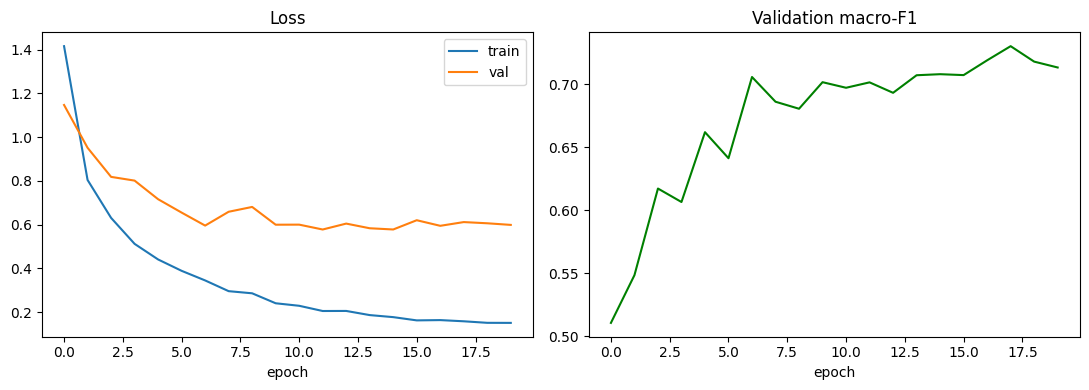

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_f1"], color="green"); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 7. Evaluation — precision / recall / F1 + confusion matrix

Now we judge the best model on the **held-out test set** it has never seen.
- **Precision**: of everything called class X, how much was actually X?
- **Recall**: of all real class X, how much did we catch? (For cancer, this is the one to watch.)
- **F1**: harmonic mean of the two.

In [26]:
ckpt = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
model.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, leave=False):
        out = model(imgs.to(DEVICE))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_true.extend(labels.numpy())

target_names = [f"{c} ({FULL_NAMES[c]})" for c in CLASSES]
print(classification_report(all_true, all_preds, labels=list(range(len(CLASSES))),
                            target_names=target_names, digits=3))

  0%|          | 0/47 [00:00<?, ?it/s]

                                     precision    recall  f1-score   support

akiec (Actinic keratoses / Bowen's)      0.648     0.730     0.687        63
         bcc (Basal cell carcinoma)      0.739     0.750     0.745        68
             bkl (Benign keratosis)      0.646     0.757     0.697       152
                df (Dermatofibroma)      0.385     0.714     0.500         7
                     mel (Melanoma)      0.487     0.679     0.567       187
             nv (Melanocytic nevus)      0.948     0.838     0.890       996
             vasc (Vascular lesion)      0.857     0.857     0.857        21

                           accuracy                          0.801      1494
                          macro avg      0.673     0.761     0.706      1494
                       weighted avg      0.833     0.801     0.812      1494



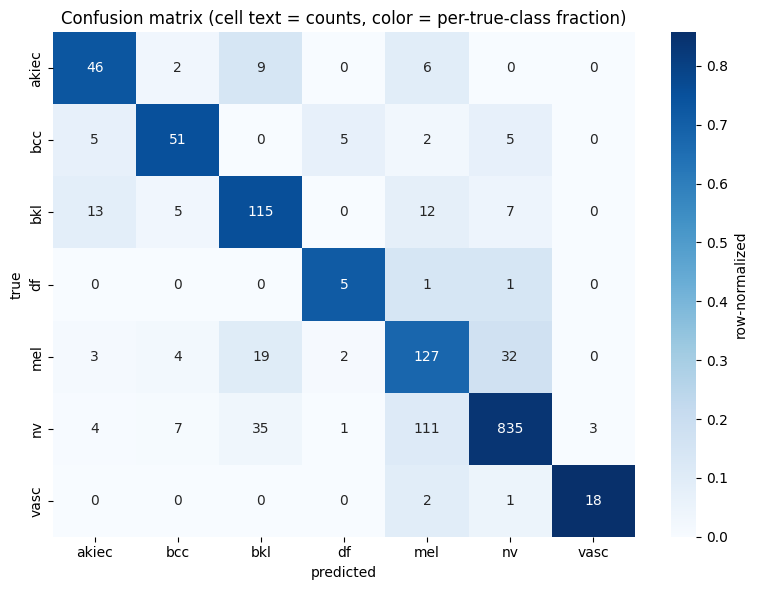

In [27]:
cm = confusion_matrix(all_true, all_preds, labels=list(range(len(CLASSES))))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, cbar_kws={"label": "row-normalized"})
plt.xlabel("predicted"); plt.ylabel("true")
plt.title("Confusion matrix (cell text = counts, color = per-true-class fraction)")
plt.tight_layout(); plt.show()

In [28]:
# The number that matters most for a skin-cancer screen: melanoma recall.
report = classification_report(all_true, all_preds, labels=list(range(len(CLASSES))),
                               target_names=CLASSES, output_dict=True)
mel_recall = report["mel"]["recall"]
print(f"Melanoma (mel) recall: {mel_recall:.1%}")
print(f"  -> Of every 100 real melanomas in the test set, this model flags ~{round(mel_recall*100)}.")
if mel_recall < 0.85:
    print("  WARNING: a screen that misses this many melanomas would be unsafe in the real world.")
print("\nReminder: this is dermatoscopic data. Real phone-photo performance will be lower.")

Melanoma (mel) recall: 67.9%
  -> Of every 100 real melanomas in the test set, this model flags ~68.

Reminder: this is dermatoscopic data. Real phone-photo performance will be lower.


## 8. Single-image inference demo (top-3 guesses)

This mirrors how the eventual app would behave: feed one image, show the top guesses with
their probabilities. `predict_top_k` is the function a FastAPI backend would call.

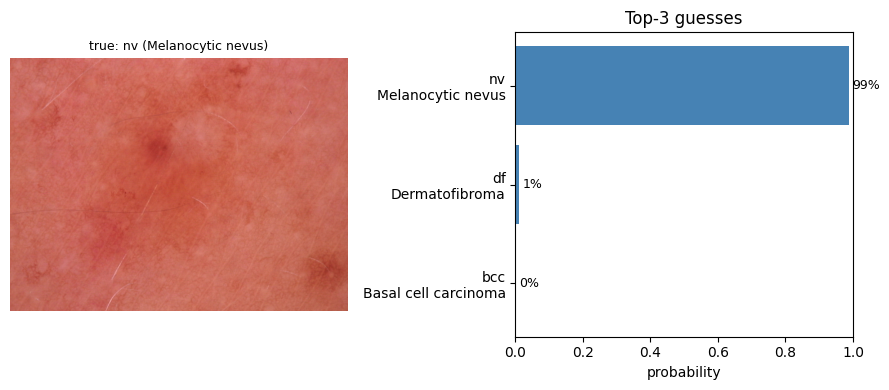

Top-3: [('nv', '98.8%'), ('df', '1.1%'), ('bcc', '0.1%')]


In [29]:
def predict_top_k(image, k=3):
    # image: a file path or a PIL.Image. Returns list of (class_code, full_name, prob).
    if not isinstance(image, Image.Image):
        image = Image.open(image).convert("RGB")
    x = eval_tf(image).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1).squeeze(0).cpu().numpy()
    top = probs.argsort()[::-1][:k]
    return [(CLASSES[i], FULL_NAMES[CLASSES[i]], float(probs[i])) for i in top]

# Demo on a random test image.
sample = test_df.sample(1, random_state=SEED).iloc[0]
preds = predict_top_k(sample["path"], k=3)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(Image.open(sample["path"]).convert("RGB")); ax[0].axis("off")
ax[0].set_title(f"true: {sample['dx']} ({FULL_NAMES[sample['dx']]})", fontsize=9)
labels = [f"{c}\n{n}" for c, n, _ in preds][::-1]
vals = [p for _, _, p in preds][::-1]
ax[1].barh(labels, vals, color="steelblue")
ax[1].set_xlim(0, 1); ax[1].set_title("Top-3 guesses"); ax[1].set_xlabel("probability")
for i, v in enumerate(vals):
    ax[1].text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

print("Top-3:", [(c, f"{p:.1%}") for c, _, p in preds])

## 9. Save the model

In [30]:
# The best model was already saved during training. Confirm it + show how to reload it.
print("Saved checkpoint:", BEST_MODEL_PATH.resolve(),
      f"({BEST_MODEL_PATH.stat().st_size/1e6:.1f} MB)")

# To reload later (e.g., inside a FastAPI backend):
#   ckpt = torch.load("skin_classifier_efficientnet_b0.pt", map_location="cpu")
#   model = build_model(len(ckpt["classes"]))
#   model.load_state_dict(ckpt["model_state"]); model.eval()
# On Colab, download the file with:
#   from google.colab import files; files.download(str(BEST_MODEL_PATH))

Saved checkpoint: /content/skin_classifier_efficientnet_b0.pt (16.4 MB)


## 10. Limitations & next steps

You now have a working baseline. Before trusting any number here, re-read `docs/ETHICS.md`.
The headline caveats:

- **Dermatoscope vs. phone gap** — these are magnified clinical images; real phone photos
  will score much lower.
- **Skin-tone bias** — HAM10000 skews toward lighter skin; fairness across tones is unverified.
- **7 classes only** — the model cannot say "not a lesion" or "unknown"; it forces every image
  into one of 7 buckets.

**Good next steps:**
1. Train longer (`EPOCHS = 20`) and compare macro-F1 / melanoma recall.
2. Add **Grad-CAM** to visualize where the model looks.
3. Try **EfficientNet-B3** or a **ViT** and compare.
4. Wrap `predict_top_k` in a small **desktop app** (drag in a photo, see the top guesses).
   That's my next milestone; the phone app comes after, reusing the same model behind an API.

Remember: being able to explain *why this shouldn't be trusted as a diagnosis* is the most
valuable thing you can demo from this project.